# Walkthrough: PSC



$$
t_{\mathrm{flight}}=\frac{L\lambda}{3956.0346}
$$

Use $L$ in metres, $\lambda$ in ångströms, and time in seconds.

In [1]:
from pathlib import Path
import mcstasscript as ms

instr = ms.McStas_instr(
    "PulseChopper",
    author="McStasScript example",
    origin="Teaching example",
)


## 1. Set the source timing

Define the source pulse duration, moderator timing parameters, repetition rate, and wavelength range here.

In [2]:
pulse_length = 400.0e-6
instr.add_parameter("pulse_length", value=pulse_length,
                    comment="Proton pulse duration for the moderator model [s]")
moderator_tau = 170.0e-6
instr.add_parameter("moderator_tau", value=moderator_tau,
                    comment="Cold moderator decay time used by Source_pulsed [s]")
moderator_n = 5.0
instr.add_parameter("moderator_n", value=moderator_n,
                    comment="Cold moderator pulse-shape parameter used by Source_pulsed")
moderator_time_center = 0.5*pulse_length + moderator_tau*(moderator_n+1.0)/moderator_n
source_frequency = 50.0
instr.add_parameter("source_frequency", value=source_frequency,
                    comment="Source repetition rate [Hz]")
lambda_min = 0.5
instr.add_parameter("lambda_min", value=lambda_min,
                    comment="Minimum source wavelength [Angstrom]")
lambda_max = 10.0
instr.add_parameter("lambda_max", value=lambda_max,
                    comment="Maximum source wavelength [Angstrom]")

l1 = 2.0
instr.add_parameter("l1", value=l1,
                    comment="Length of first guide segment [m]")


Parameter named: 'l1' with value: 2.0
 [dimensionless]
 Length of first guide segment [m]

## 2. Add the source and first guide

Run the next cell to create `Source_pulsed`, then place the guide entrance 0.1 m downstream. The source samples wavelength and emission time and assigns a weight using the moderator spectrum and time profile.

Read the source parameters in these groups before running the cell:

| Parameter | Value in this example | Meaning |
| --- | --- | --- |
| `xwidth`, `yheight` | 0.042 m, 0.03 m | Width and height of the emitting surface. |
| `Lmin`, `Lmax` | 0.5–10 Å | Wavelength sampling range; this is wider than the target chopper band. |
| `t_min`, `t_max` | 0–0.004 s | Emission-time sampling window. It includes the moderator tail; it is not the proton pulse duration. |
| `freq` | 50 Hz | Source repetition rate: one source period is 20 ms. |
| `t_pulse` | 400 µs | Proton pulse duration that drives the moderator model. |
| `dist` | 0.1 m | Distance to the focusing plane. |
| `focus_xw`, `focus_yh` | 0.04 m, 0.04 m | Size of the target at that plane, matching the guide entrance. |
| `T1` | 60 K | Temperature parameter for the cold moderator spectrum. |
| `I1` | `1.75e12/source_frequency` | Cold moderator intensity coefficient, scaled by the source rate in this example. |
| `tau1`, `n_mod` | 170 µs, 5 | Cold moderator decay-time and pulse-shape parameters. |
| `I_um` | `3.82e10/source_frequency` | Intensity coefficient for the additional moderator contribution. |
| `tau_um`, `n_um` | 12 µs, 5 | Timing and shape parameters for that contribution. |
| `chi_um`, `kap_um` | 0.9, 2.2 | Additional spectrum-shape parameters of the moderator model. |

1. The source emits over a finite time distribution. The timing code uses the approximate cold-moderator center
   $$\bar t_s=\frac{t_{\mathrm{pulse}}}{2}+\tau_1\frac{n+1}{n}=200+170\frac{6}{5}=404\;\mu\mathrm{s}.$$
   This is the timing reference used by the notebook, rather than the peak or full width of the complete source distribution.
2. A neutron travels at $v=3956.0346/\lambda$ m/s when $\lambda$ is in Å. Therefore its flight time is $t_{\mathrm{flight}}=L\lambda/3956.0346$ seconds.
3. Add emission time and flight time to predict its arrival at a downstream component: $t_{\mathrm{arrival}}\approx\bar t_s+L\lambda/3956.0346$.
4. The straight guide has 0.04 m entrance and exit dimensions, length `l1` = 2 m, and supermirror parameter `m` = 4. Its `AT` position marks its entrance, so its exit is 2.1 m from the source.


In [3]:
source = instr.add_component("source", "Source_pulsed")
source.xwidth = 0.042
source.yheight = 0.03
source.Lmin = "lambda_min"
source.Lmax = "lambda_max"
source.t_min = 0.0
source.t_max = 0.004
source.dist = 0.1
source.focus_xw = 0.04
source.focus_yh = 0.04
source.freq = "source_frequency"
source.t_pulse = "pulse_length"
# HBS-style cold moderator example parameters documented by Source_pulsed.
source.T1 = 60.0
source.I1 = "1.75e12/source_frequency"
source.tau1 = "moderator_tau"
source.n_mod = "moderator_n"
source.I_um = "3.82e10/source_frequency"
source.tau_um = 12.0e-6
source.n_um = 5.0
source.chi_um = 0.9
source.kap_um = 2.2

# Straight guide after the moderator. 
guide = instr.add_component(
    "guide", "Guide", AT=[0, 0, 0.1], RELATIVE="source"
)
guide.w1 = 0.04
guide.h1 = 0.04
guide.w2 = 0.04
guide.h2 = 0.04
guide.l = "l1"
guide.m = 4.0


## 3. Choose the PSC settings

**Do:** Start with the given values. Then try changing `psc_order` or the target wavelength limits and rerun from the top.

**Equation:** $f_{\mathrm{PSC}}=qf_s$ and $w_{\mathrm{PSC}}=\theta/(360^\circ f_{\mathrm{PSC}})$. With $q=1$, $f_s=50$ Hz, and $\theta=36^\circ$, the open time is 2 ms. The nominal band window is $w_{\mathrm{target}}=t_{\mathrm{pulse}}+L(\lambda_{\max}-\lambda_{\min})/3956.0346$.

In [4]:

# Set the PSC order relative to the 50 Hz source. Increase this integer
# to raise the rotor frequency and shorten the gate.
psc_order = 1
instr.add_parameter("psc_order", value=psc_order,
                    comment="PSC frequency = psc_order times source frequency")
opening_PSC = 36.0
instr.add_parameter("opening_PSC", value=opening_PSC,
                    comment="PSC slit angular opening [degrees]")
chopper_distance = l1+0.12
instr.add_parameter("chopper_distance", value=chopper_distance,
                    comment="Source-to-PSC distance [m]")

psc_lambda_min = 1.0
instr.add_parameter("psc_lambda_min", value=psc_lambda_min,
                    comment="Lower wavelength edge to center on with the PSC [Angstrom]")
psc_lambda_max = 7.0
instr.add_parameter("psc_lambda_max", value=psc_lambda_max,
                    comment="Upper wavelength edge to center on with the PSC [Angstrom]")
lambda_center = 0.5 * (psc_lambda_min + psc_lambda_max)


## 5. Measure the beam before the PSC


In [5]:
lambda_before_PSC = instr.add_component(
    "lambda_before_PSC", "L_monitor", AT=[0, 0, "l1+0.005"], RELATIVE="guide"
)
lambda_before_PSC.xwidth = 0.04
lambda_before_PSC.yheight = 0.04
lambda_before_PSC.nL = 100
lambda_before_PSC.Lmin = 0.5
lambda_before_PSC.Lmax = 10.0
lambda_before_PSC.restore_neutron = 1

tof_before_PSC = instr.add_component(
    "tof_before_PSC", "TOF_monitor", AT=[0, 0, "l1+0.005"], RELATIVE="guide"
)
tof_before_PSC.xwidth = 0.04
tof_before_PSC.yheight = 0.04
tof_before_PSC.nt = 1000
tof_before_PSC.tmin = 0.0
tof_before_PSC.tmax = 10000.0
tof_before_PSC.restore_neutron = 1

## 6. Run the beam without the PSC


---- Found 1 places in McStas output with keyword 'error'. 

[mac-pro:2989063] Set MCA parameter "orte_base_help_aggregate" to 0 to see all help / error messages
*** TRACE end *** 
Detector: lambda_before_PSC_I=3.71804e+10 lambda_before_PSC_ERR=1.07502e+08 lambda_before_PSC_N=6.74134e+06 "lambda_before_PSC.dat"
Detector: tof_before_PSC_I=3.71804e+10 tof_before_PSC_ERR=1.07502e+08 tof_before_PSC_N=6.74134e+06 "tof_before_PSC.dat"
INFO: Placing instr file copy PulseChopper.instr in dataset /run/media/kyriakos2013/Crucial_X9/SCHOOL/solutions/PSC/PulseChopper
INFO: Placing generated c-code copy PulseChopper.c in dataset /run/media/kyriakos2013/Crucial_X9/SCHOOL/solutions/PSC/PulseChopper

----------------------------------------------------------------------

INFO: Using directory: "/run/media/kyriakos2013/Crucial_X9/SCHOOL/solutions/PSC/PulseChopper"
INFO: Regenerating c-file: PulseChopper.c
Info:    'Source_pulsed' is a contributed component.
CFLAGS=

------------------------------------

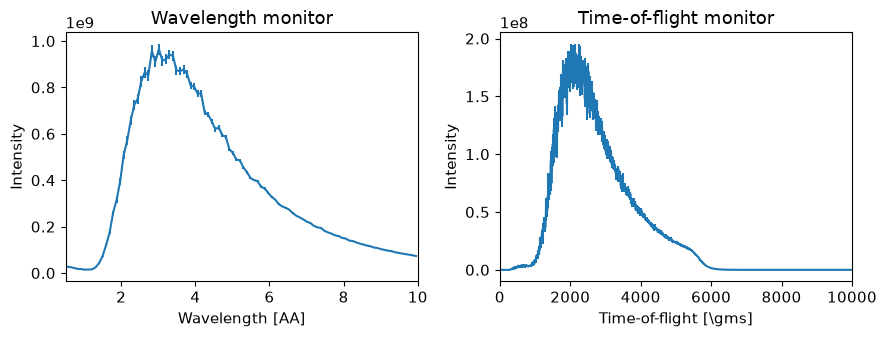

In [6]:
import os
import sys
from pathlib import Path

os.environ["MCSTAS_CC_OVERRIDE"] = "/usr/bin/gcc"
os.environ["MCSTAS_MPICC_OVERRIDE"] = str(Path(sys.prefix) / "bin" / "mpicc")
os.environ["MCSTAS_MPIRUN_OVERRIDE"] = str(Path(sys.prefix) / "bin" / "mpirun")
os.environ["OMPI_CC"] = "/usr/bin/gcc"
os.environ["MCSTAS_CFLAGS_OVERRIDE"] = "-O2 -march=x86-64 -mtune=generic -std=c99 -D_POSIX_SOURCE -lm"
os.environ["CFLAGS"] = ""
os.environ["LDFLAGS"] = ""

instr.settings(force_compile=True, ncount=1e8, mpi=12)
data=instr.backengine()
ms.make_sub_plot(data)

## 7. Add the pulse-shaping chopper

The PSC transmits neutrons when its rotating slit crosses the beam. Calculate its frequency, opening duration, and delay in that order. The cells below declare the timing variables, register their calculations, and then connect the results to `DiskChopper`.

1. **Choose the rotation frequency.** The integer `psc_order` is $q$, the number of rotations per source period:
   $$f_{\mathrm{PSC}}=qf_s=1\times50=50\;\mathrm{Hz}.$$
   This corresponds to 3000 rpm and a rotor period $T_{\mathrm{PSC}}=1/f_{\mathrm{PSC}}$ = 20 ms. With `nslit = 1`, there is one opening per rotation. Increasing $q$ produces more openings per source period.
2. **Convert slit angle to open time.** The slit occupies `opening_PSC`/360 of one revolution:
   $$w_{\mathrm{PSC}}=\frac{\theta}{360^\circ f_{\mathrm{PSC}}}=\frac{36}{360\times50}=2.000\;\mathrm{ms}.$$
   At fixed angle, doubling the frequency halves this geometric opening duration.
3. **Calculate the target arrival times.** Here `chopper_distance` gives $L$ = 2.12 m from the source, and `psc_lambda_min`, `psc_lambda_max` give 4–6 Å. Using $\bar t_s$ = 404 µs:
   $$t_{\mathrm{start}}=\bar t_s+\frac{L\lambda_{\min}}{3956.0346},\qquad
   t_{\mathrm{end}}=\bar t_s+\frac{L\lambda_{\max}}{3956.0346}.$$
   These are reference arrival times for the two band edges, using the same emission-time center; they are not the earliest and latest arrivals of the full moderator distribution.
4. **Center the slit in time.** The desired delay from the source time origin is
   $$t_c=\frac{t_{\mathrm{start}}+t_{\mathrm{end}}}{2}
   =\bar t_s+\frac{L(\lambda_{\min}+\lambda_{\max})/2}{3956.0346}
   =3.083\;\mathrm{ms}.$$
   This value is stored in `psc_phase_time`.
5. **Convert delay to angular phase.** `DiskChopper.phase` uses degrees:
   $$\phi=(360^\circ f_{\mathrm{PSC}}t_c)\bmod360^\circ=55.50^\circ.$$
   The code stores this in `psc_phase_deg`. Modulo 360 keeps the angle within one revolution. The equivalent opening-center delay is $\phi/(360^\circ f_{\mathrm{PSC}})$, modulo the rotor period; subsequent opening centers repeat every $1/f_{\mathrm{PSC}}$.

| `DiskChopper` setting | Purpose |
| --- | --- |
| `AT`, `RELATIVE` | Place the disc 2.12 m from the source on the beam centerline. |
| `radius = 0.25` | Disc radius in metres. |
| `yheight = 0.065` | Slit height in metres. |
| `theta_0 = "opening_PSC"` | Angular slit opening in degrees. |
| `nu = "nu_PSC"` | Calculated rotation frequency in Hz. |
| `nslit = 1` | One slit per disc. |
| `phase = "psc_phase_deg"` | Calculated angular delay. |
| `abs_out = 1` | Absorb neutrons outside the transmitting opening. |
| `verbose = 1` | Print chopper information during the run. |

Run the next cell, then add the downstream monitors to compare the transmitted arrival-time distribution with the incoming beam. The measured TOF FWHM can differ from the geometric gate duration.


### Declare the PSC timing variables

`add_declare_var("double", name)` declares a floating-point variable in the generated McStas instrument. It does not calculate its value. `append_initialize(...)` adds C code that calculates these values once at the start of each simulation, using the current instrument parameters.

| Variable | Meaning and units |
| --- | --- |
| `PSC_order` | Integer source harmonic copied from `psc_order`, stored as a double. |
| `nu_PSC` | Rotation frequency: `PSC_order * source_frequency` [Hz]. |
| `actual_width_PSC` | Geometric opening time: `opening_PSC / (360 * nu_PSC)` [s]. |
| `psc_source_center` | Approximate moderator emission-time center [s]. |
| `psc_band_min`, `psc_band_max` | Target wavelength edges [Å], in the PSC-only notebook. |
| `psc_phase_lambda` | Midpoint of those wavelength edges [Å], in the PSC-only notebook. |
| `psc_t_start`, `psc_t_end` | Reference arrival times of the lower and upper wavelength edges [s]. |
| `psc_target_width` | Nominal proton-pulse duration plus band flight-time spread [s]. |
| `psc_max_order` | Largest integer harmonic whose geometric opening covers that nominal span. |
| `psc_phase_time` | Desired opening-center delay, the midpoint of the edge arrival times [s]. |
| `psc_phase_deg` | That delay converted to an angle, modulo 360 [degrees]. |

Run the declarations first, then register the calculations in the following cell.


In [7]:
instr.add_declare_var("double", "nu_PSC")
instr.add_declare_var("double", "PSC_order")
instr.add_declare_var("double", "actual_width_PSC")
instr.add_declare_var("double", "psc_source_center")
instr.add_declare_var("double", "psc_phase_lambda")
instr.add_declare_var("double", "psc_phase_time")
instr.add_declare_var("double", "psc_phase_deg")
instr.add_declare_var("double", "psc_t_start")
instr.add_declare_var("double", "psc_t_end")
instr.add_declare_var("double", "psc_target_width")
instr.add_declare_var("double", "psc_band_min")
instr.add_declare_var("double", "psc_band_max")
instr.add_declare_var("double", "psc_max_order")


Declare variable: 'psc_max_order' of type double

### Register the PSC calculations and checks


In [8]:
instr.append_initialize(
    'if (moderator_tau <= 0 || moderator_n <= 1 || source_frequency <= 0 || psc_order < 1 || fabs(psc_order-floor(psc_order+0.5)) > 1e-6 || opening_PSC <= 0 || opening_PSC >= 360 || psc_lambda_min < lambda_min || psc_lambda_max > lambda_max || psc_lambda_min <= 0 || psc_lambda_max <= psc_lambda_min) { fprintf(stderr, "PSC band must be within the source range; order, source frequency and slit opening must be valid\\n"); exit(1); }'
)
instr.append_initialize("psc_band_min = psc_lambda_min;")
instr.append_initialize("psc_band_max = psc_lambda_max;")
instr.append_initialize("psc_phase_lambda = (psc_band_min + psc_band_max)/2.0;")
instr.append_initialize("PSC_order = psc_order;")
instr.append_initialize("nu_PSC = PSC_order*source_frequency;")
instr.append_initialize("actual_width_PSC = opening_PSC/(360.0*nu_PSC);")
instr.append_initialize("psc_source_center = 0.5*pulse_length + moderator_tau*(moderator_n+1.0)/moderator_n;")
instr.append_initialize("psc_t_start = psc_source_center + chopper_distance*psc_band_min/3956.0346;")
instr.append_initialize("psc_t_end = psc_source_center + chopper_distance*psc_band_max/3956.0346;")
instr.append_initialize("psc_target_width = pulse_length + chopper_distance*(psc_band_max-psc_band_min)/3956.0346;")
instr.append_initialize("psc_max_order = floor(opening_PSC/(360.0*source_frequency*psc_target_width));")
instr.append_initialize('if (actual_width_PSC + 1e-12 < psc_target_width) { printf("WARNING: PSC gate is narrower than the nominal source-pulse plus target-band arrival span; band edges will be clipped\\n"); }')
instr.append_initialize("psc_phase_time = 0.5*(psc_t_start + psc_t_end);")
instr.append_initialize("psc_phase_deg = fmod(360.0*nu_PSC*psc_phase_time, 360.0);")
instr.append_initialize('printf("PSC order=%g, rate=%g Hz (%g rpm), gate=%g us, nominal gate requirement=%g us, largest nominal order=%g; source center=%g ms; phase=%g deg at t=%g ms\\n", PSC_order, nu_PSC, 60.0*nu_PSC, actual_width_PSC*1e6, psc_target_width*1e6, psc_max_order, 1e3*psc_source_center, psc_phase_deg, 1e3*psc_phase_time);')
instr.append_initialize(
    'if (chopper_distance < 0.1 + l1 + 0.02) { printf("PSC is too close to guide 1; increase chopper_distance or reduce l1\\n"); exit(1); }'
)


### Create the PSC component



In [9]:

psc = instr.add_component(
    "PSC", "DiskChopper",
    AT=[0, 0, "chopper_distance"], RELATIVE="source",
)
psc.radius = 0.25
psc.yheight = 0.065  
psc.theta_0 = "opening_PSC"
psc.nu = "nu_PSC"
psc.nslit = 1
psc.phase = "psc_phase_deg"
psc.abs_out = 1
psc.verbose = 1  

## 8. Measure the beam after the PSC

In [10]:
lambda_after_PSC = instr.add_component(
    "lambda_after_PSC", "L_monitor", AT=[0, 0, 0.005], RELATIVE="PSC"
)
lambda_after_PSC.xwidth = 0.04
lambda_after_PSC.yheight = 0.04
lambda_after_PSC.nL = 100
lambda_after_PSC.Lmin = 0.5
lambda_after_PSC.Lmax = 10.0
lambda_after_PSC.restore_neutron = 1

tof_after_PSC = instr.add_component(
    "tof_after_PSC", "TOF_monitor", AT=[0, 0, 0.005], RELATIVE="PSC"
)
tof_after_PSC.xwidth = 0.04
tof_after_PSC.yheight = 0.04
tof_after_PSC.nt = 1000
tof_after_PSC.tmin = 0.0
tof_after_PSC.tmax = 10000.0
tof_after_PSC.restore_neutron = 1

## 9. Run the chopper model


---- Found 1 places in McStas output with keyword 'error'. 

[mac-pro:2989569] Set MCA parameter "orte_base_help_aggregate" to 0 to see all help / error messages
*** TRACE end *** 
Detector: lambda_before_PSC_I=3.7011e+10 lambda_before_PSC_ERR=1.07135e+08 lambda_before_PSC_N=6.74638e+06 "lambda_before_PSC.dat"
Detector: tof_before_PSC_I=3.7011e+10 tof_before_PSC_ERR=1.07135e+08 tof_before_PSC_N=6.74638e+06 "tof_before_PSC.dat"
Detector: lambda_after_PSC_I=2.58551e+10 lambda_after_PSC_ERR=9.74649e+07 lambda_after_PSC_N=440443 "lambda_after_PSC.dat"
Detector: tof_after_PSC_I=2.58551e+10 tof_after_PSC_ERR=9.74649e+07 tof_after_PSC_N=440443 "tof_after_PSC.dat"
INFO: Placing instr file copy PulseChopper.instr in dataset /run/media/kyriakos2013/Crucial_X9/SCHOOL/solutions/PSC/PulseChopper_0
INFO: Placing generated c-code copy PulseChopper.c in dataset /run/media/kyriakos2013/Crucial_X9/SCHOOL/solutions/PSC/PulseChopper_0

----------------------------------------------------------------------

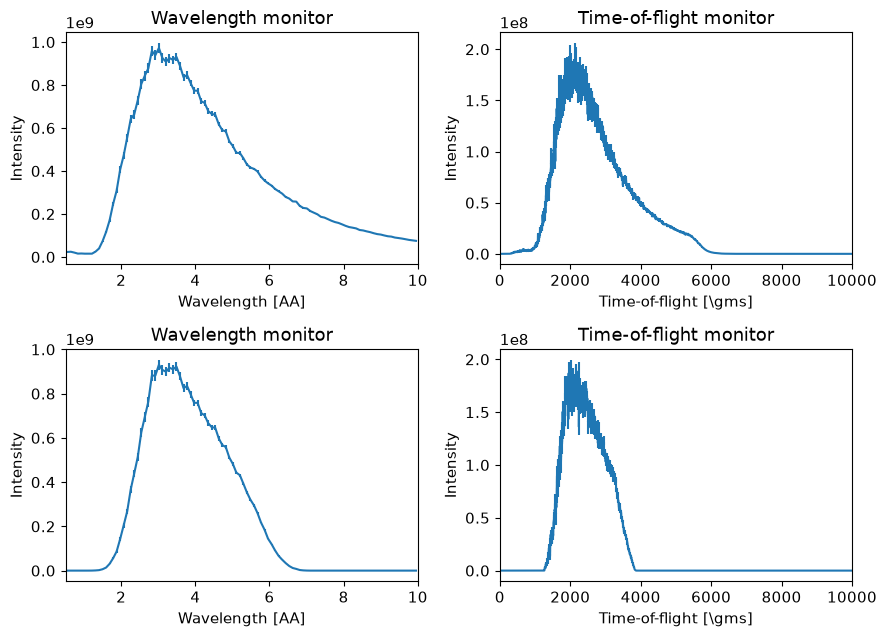

In [11]:
# CPU-compatible McStas build settings 
import os
import sys
from pathlib import Path

os.environ["MCSTAS_CC_OVERRIDE"] = "/usr/bin/gcc"
os.environ["MCSTAS_MPICC_OVERRIDE"] = str(Path(sys.prefix) / "bin" / "mpicc")
os.environ["MCSTAS_MPIRUN_OVERRIDE"] = str(Path(sys.prefix) / "bin" / "mpirun")
os.environ["OMPI_CC"] = "/usr/bin/gcc"
os.environ["MCSTAS_CFLAGS_OVERRIDE"] = "-O2 -march=x86-64 -mtune=generic -std=c99 -D_POSIX_SOURCE -lm"
os.environ["CFLAGS"] = ""
os.environ["LDFLAGS"] = ""

instr.settings(force_compile=True, ncount=1e8, mpi=12)
data=instr.backengine()
ms.make_sub_plot(data)

## 10. Compare one pulse

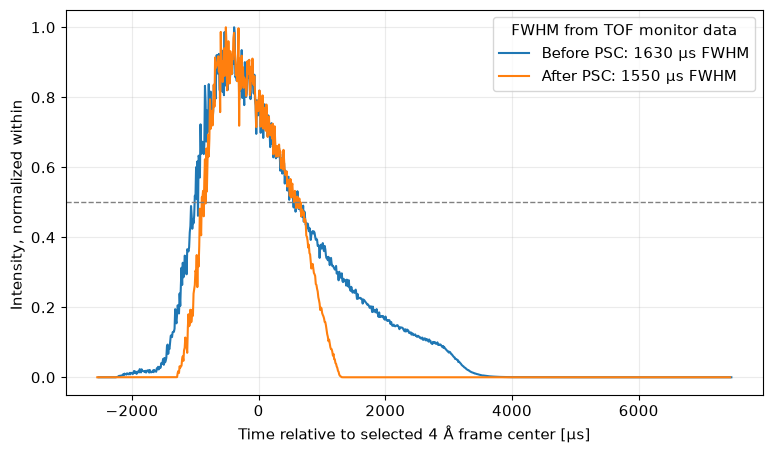

PSC rate: 50 Hz (3000 rpm)
Calculated slit gate width: 2000.0 µs
Geometric gate from slit angle: 2000.0 µs
Before PSC FWHM in selected frame: 1630.0 µs
After PSC FWHM in selected frame:  1550.0 µs


In [12]:
import numpy as np
import matplotlib.pyplot as plt

before = next(d for d in data if d.name == "tof_before_PSC")
after = next(d for d in data if d.name == "tof_after_PSC")

psc_order = int(round(float(psc_order)))
psc_frequency = psc_order * source_frequency
psc_period_us = 1e6 / psc_frequency

center_before_us = (moderator_time_center + (0.1 + l1 + 0.005) * lambda_center / 3956.034) * 1e6
center_after_us = (moderator_time_center + (chopper_distance + 0.005) * lambda_center / 3956.034) * 1e6
half_frame_us = psc_period_us / 2

def frame_profile(monitor, center_us):
    time_us = np.asarray(monitor.xaxis, dtype=float)
    intensity = np.asarray(monitor.Intensity, dtype=float)
    keep = (time_us >= center_us - half_frame_us) & (time_us <= center_us + half_frame_us)
    time_us, intensity = time_us[keep], intensity[keep]
    if len(time_us) < 2 or np.max(intensity) <= 0:
        raise ValueError(f"No TOF signal in selected PSC frame for {monitor.name}")
    half_max = np.max(intensity) / 2
    bins = np.flatnonzero(intensity >= half_max)
    bin_width = np.median(np.diff(time_us))
    width_us = time_us[bins[-1]] - time_us[bins[0]] + bin_width
    return time_us - center_us, intensity / np.max(intensity), width_us

relative_before, norm_before, width_before = frame_profile(before, center_before_us)
relative_after, norm_after, width_after = frame_profile(after, center_after_us)

plt.figure(figsize=(9, 5))
plt.plot(relative_before, norm_before, label=f"Before PSC: {width_before:.0f} µs FWHM")
plt.plot(relative_after, norm_after, label=f"After PSC: {width_after:.0f} µs FWHM")
plt.axhline(0.5, color="gray", linestyle="--", linewidth=1)
plt.xlabel(f"Time relative to selected {lambda_center:g} Å frame center [µs]")
plt.ylabel("Intensity, normalized within ")
plt.grid(alpha=0.25)
plt.legend(title="FWHM from TOF monitor data")
plt.show()

print(f"PSC rate: {psc_frequency:g} Hz ({psc_frequency*60:g} rpm)")
print(f"Calculated slit gate width: {opening_PSC/(360.0*psc_frequency)*1e6:.1f} µs")
print(f"Geometric gate from slit angle: {opening_PSC/(360*psc_frequency)*1e6:.1f} µs")
print(f"Before PSC FWHM in selected frame: {width_before:.1f} µs")
print(f"After PSC FWHM in selected frame:  {width_after:.1f} µs")


## 11. Change the PSC frequency

**Do:** Run the sweep to compare several integer source harmonics. It keeps the slit angle and source frequency fixed, and changes only $q$.


**Wavelength comparison:** The same runs also supply `lambda_after_PSC`. The added plot overlays the transmitted wavelength spectra for each PSC frequency, normalizing each spectrum to its own maximum, just like the TOF profiles. The shaded region marks the PSC target range. Normalization compares shapes rather than absolute transmitted intensity.

The wavelength monitor integrates over arrival time, whereas the TOF comparison selects one opening near the target arrival time. At higher orders, repeated openings can produce several wavelength transmission regions; the spectrum is not restricted to that one TOF frame.


---- Found 1 places in McStas output with keyword 'error'. 

[mac-pro:2990202] Set MCA parameter "orte_base_help_aggregate" to 0 to see all help / error messages
*** TRACE end *** 
Detector: lambda_before_PSC_I=3.72643e+10 lambda_before_PSC_ERR=1.07655e+08 lambda_before_PSC_N=6.74359e+06 "lambda_before_PSC.dat"
Detector: tof_before_PSC_I=3.72643e+10 tof_before_PSC_ERR=1.07655e+08 tof_before_PSC_N=6.74359e+06 "tof_before_PSC.dat"
Detector: lambda_after_PSC_I=2.59888e+10 lambda_after_PSC_ERR=9.75738e+07 lambda_after_PSC_N=441670 "lambda_after_PSC.dat"
Detector: tof_after_PSC_I=2.59888e+10 tof_after_PSC_ERR=9.75738e+07 tof_after_PSC_N=441670 "tof_after_PSC.dat"
INFO: Placing instr file copy PulseChopper.instr in dataset /run/media/kyriakos2013/Crucial_X9/SCHOOL/solutions/PSC/PulseChopper_1
INFO: Placing generated c-code copy PulseChopper.c in dataset /run/media/kyriakos2013/Crucial_X9/SCHOOL/solutions/PSC/PulseChopper_1

--------------------------------------------------------------------

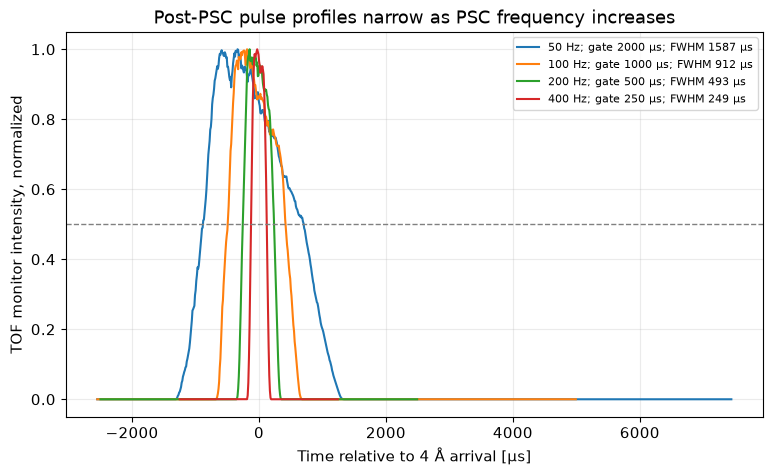

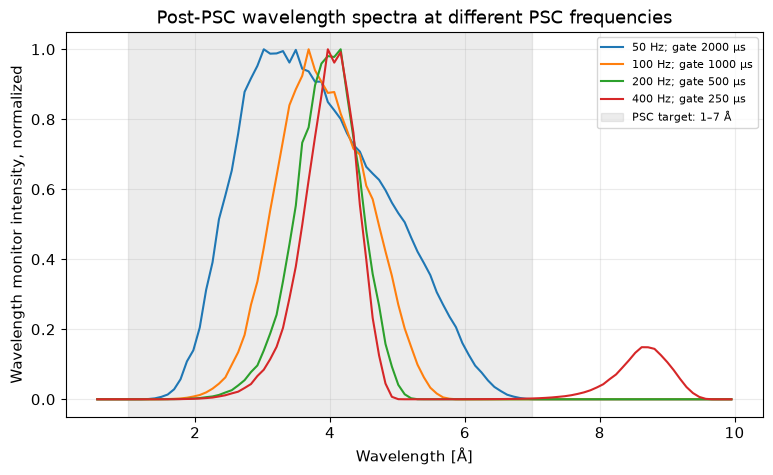

PSC 50 Hz: geometric gate 2000.0 µs; post-PSC TOF FWHM 1587.0 µs
PSC 100 Hz: geometric gate 1000.0 µs; post-PSC TOF FWHM 911.7 µs
PSC 200 Hz: geometric gate 500.0 µs; post-PSC TOF FWHM 493.2 µs
PSC 400 Hz: geometric gate 250.0 µs; post-PSC TOF FWHM 248.6 µs


In [13]:
import os
import sys
from pathlib import Path

os.environ["MCSTAS_CC_OVERRIDE"] = "/usr/bin/gcc"
os.environ["MCSTAS_MPICC_OVERRIDE"] = str(Path(sys.prefix) / "bin" / "mpicc")
os.environ["MCSTAS_MPIRUN_OVERRIDE"] = str(Path(sys.prefix) / "bin" / "mpirun")
os.environ["OMPI_CC"] = "/usr/bin/gcc"
os.environ["MCSTAS_CFLAGS_OVERRIDE"] = "-O2 -march=x86-64 -mtune=generic -std=c99 -D_POSIX_SOURCE -lm"
os.environ["CFLAGS"] = ""
os.environ["LDFLAGS"] = ""

import numpy as np
import matplotlib.pyplot as plt

psc_orders_to_compare = [1, 2, 4, 8]
base_psc_order = int(round(float(psc_order)))
instr.settings(force_compile=True, ncount=1e8, mpi=12)
frequency_sweep = []
pulse_profiles = []
wavelength_profiles = []

frame_center_us = (moderator_time_center + (chopper_distance + 0.005)*lambda_center/3956.034) * 1e6

def smooth_monitor_fwhm(monitor, center_us, half_period_us):
    time_us = np.asarray(monitor.xaxis, dtype=float)
    intensity = np.asarray(monitor.Intensity, dtype=float)
    keep = (time_us >= center_us-half_period_us) & (time_us <= center_us+half_period_us)
    time_us, intensity = time_us[keep], intensity[keep]
    if len(time_us) < 5 or np.max(intensity) <= 0:
        return None
    smoothed = np.convolve(intensity, np.ones(5)/5.0, mode="same")
    peak = int(np.argmax(smoothed))
    half_max = smoothed[peak]/2.0
    left, right = peak, peak
    while left > 0 and smoothed[left-1] >= half_max:
        left -= 1
    while right+1 < len(smoothed) and smoothed[right+1] >= half_max:
        right += 1
    if left == 0 or right == len(smoothed)-1:
        return None
    t_left = np.interp(half_max, [smoothed[left-1], smoothed[left]], [time_us[left-1], time_us[left]])
    t_right = np.interp(half_max, [smoothed[right+1], smoothed[right]], [time_us[right+1], time_us[right]])
    width_us = t_right-t_left
    return time_us-center_us, smoothed/np.max(smoothed), width_us

for order in psc_orders_to_compare:
    instr.set_parameters(psc_order=int(order))
    sweep_data = instr.backengine()
    monitor = next(d for d in sweep_data if d.name == "tof_after_PSC")
    frequency_hz = order*source_frequency
    gate_us = opening_PSC/(360.0*frequency_hz)*1e6
    profile = smooth_monitor_fwhm(monitor, frame_center_us, 0.5e6/frequency_hz)
    if profile is None:
        relative_t, normalized, fwhm_us = np.array([]), np.array([]), np.nan
    else:
        relative_t, normalized, fwhm_us = profile
    frequency_sweep.append((frequency_hz, gate_us, fwhm_us))
    pulse_profiles.append((frequency_hz, gate_us, fwhm_us, relative_t, normalized))

    # Reuse the wavelength monitor from this same simulation.
    wavelength_monitor = next(d for d in sweep_data if d.name == "lambda_after_PSC")
    wavelength = np.asarray(wavelength_monitor.xaxis, dtype=float)
    wavelength_intensity = np.asarray(wavelength_monitor.Intensity, dtype=float)
    peak_intensity = np.max(wavelength_intensity) if wavelength_intensity.size else 0.0
    if peak_intensity > 0:
        wavelength_profiles.append((frequency_hz, gate_us, wavelength,
                                    wavelength_intensity / peak_intensity))
    else:
        print(f"PSC {frequency_hz:g} Hz: no post-PSC wavelength signal")

plt.figure(figsize=(9, 5))
for frequency_hz, gate_us, fwhm_us, relative_t, normalized in pulse_profiles:
    if len(relative_t):
        plt.plot(relative_t, normalized, label=f"{frequency_hz:g} Hz; gate {gate_us:.0f} µs; FWHM {fwhm_us:.0f} µs")
plt.axhline(0.5, color="gray", linestyle="--", linewidth=1)
plt.xlabel(f"Time relative to {lambda_center:g} Å arrival [µs]")
plt.ylabel("TOF monitor intensity, normalized")
plt.title("Post-PSC pulse profiles narrow as PSC frequency increases")
plt.grid(alpha=0.25)
plt.legend(fontsize=8)
plt.show()

plt.figure(figsize=(9, 5))
for frequency_hz, gate_us, wavelength, normalized_lambda in wavelength_profiles:
    plt.plot(wavelength, normalized_lambda,
             label=f"{frequency_hz:g} Hz; gate {gate_us:.0f} µs")
plt.axvspan(psc_lambda_min, psc_lambda_max, color="gray", alpha=0.15,
            label=f"PSC target: {psc_lambda_min:g}–{psc_lambda_max:g} Å")
plt.xlabel("Wavelength [Å]")
plt.ylabel("Wavelength monitor intensity, normalized")
plt.title("Post-PSC wavelength spectra at different PSC frequencies")
plt.grid(alpha=0.25)
plt.legend(fontsize=8)
plt.show()

frequency_sweep = np.asarray(frequency_sweep, dtype=float)


for frequency_hz, gate_us, fwhm_us in frequency_sweep:
    print(f"PSC {frequency_hz:.0f} Hz: geometric gate {gate_us:.1f} µs; post-PSC TOF FWHM {fwhm_us:.1f} µs")

instr.set_parameters(psc_order=base_psc_order)
